In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv(r"D:\Data Analyst\Projects\Bank Loan Portfolio\1. Dataset\Bank_Loan_Data_Cleaned.csv")

In [18]:
# Display first 5 rows
display(df.head())

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("Columns:", df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

,Loan_ID,State,Application_Type,Emp_Length,Emp_Title,Loan_Grade,Home_Ownership,Issue_Date,Last_Credit_Pull_Date,Last_Payment_Date,...,Loan_Sub_Grade,Loan_Term,Verification_Status,Annual_Income,Debt_To_Income_Ratio,Monthly_Installment,Interest_Rate,Loan_Amount,Total_Accounts,Total_Amount_Paid
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2/11/2021,9/13/2021,4/13/2021,...,C4,60 months,Source Verified,"$30,000.00",0.0100,59.83,0.1527,"$2,500.00",4,"$1,009.00"
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,1/1/2021,12/14/2021,1/15/2021,...,E1,36 months,Source Verified,"$48,000.00",0.0535,109.43,0.1864,"$3,000.00",4,"$3,939.00"
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,1/5/2021,12/12/2021,1/9/2021,...,C5,36 months,Not Verified,"$50,000.00",0.2088,421.65,0.1596,"$12,000.00",11,"$3,522.00"
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2/25/2021,12/12/2021,3/12/2021,...,B2,60 months,Source Verified,"$42,000.00",0.0540,97.06,0.1065,"$4,500.00",9,"$4,911.00"
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,1/1/2021,12/14/2021,1/15/2021,...,A1,36 months,Verified,"$83,000.00",0.0231,106.53,0.0603,"$3,500.00",28,"$3,835.00"


Dataset Shape: (38576, 24)
Columns: ['Loan_ID', 'State', 'Application_Type', 'Emp_Length', 'Emp_Title', 'Loan_Grade', 'Home_Ownership', 'Issue_Date', 'Last_Credit_Pull_Date', 'Last_Payment_Date', 'Loan_Status', 'Next_Payment_Date', 'Member_ID', 'Purpose', 'Loan_Sub_Grade', 'Loan_Term', 'Verification_Status', 'Annual_Income', 'Debt_To_Income_Ratio', 'Monthly_Installment', 'Interest_Rate', 'Loan_Amount', 'Total_Accounts', 'Total_Amount_Paid']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Loan_ID                38576 non-null  int64  
 1   State                  38576 non-null  object 
 2   Application_Type       38576 non-null  object 
 3   Emp_Length             38576 non-null  object 
 4   Emp_Title              38571 non-null  object 
 5   Loan_Grade             38576 non-null  object 
 6   Home_Ownership         38

,Loan_ID,Member_ID,Debt_To_Income_Ratio,Monthly_Installment,Interest_Rate,Total_Accounts
count,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,8.476515e+05,0.133274,326.862965,0.120488,22.132544
std,2.113246e+05,2.668105e+05,0.066662,209.092000,0.037164,11.392282
min,5.473400e+04,7.069900e+04,0.000000,15.690000,0.054200,2.000000
25%,5.135170e+05,6.629788e+05,0.082100,168.450000,0.093200,14.000000
50%,6.627280e+05,8.473565e+05,0.134200,283.045000,0.118600,20.000000
75%,8.365060e+05,1.045652e+06,0.185900,434.442500,0.145900,29.000000
max,1.077501e+06,1.314167e+06,0.299900,1305.190000,0.245900,90.000000


In [19]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate Loan IDs
print("Duplicate Loan IDs:", df["Loan_ID"].duplicated().sum())

Missing Values:
Loan_ID                  0
State                    0
Application_Type         0
Emp_Length               0
Emp_Title                5
Loan_Grade               0
Home_Ownership           0
Issue_Date               0
Last_Credit_Pull_Date    0
Last_Payment_Date        0
Loan_Status              0
Next_Payment_Date        0
Member_ID                0
Purpose                  0
Loan_Sub_Grade           0
Loan_Term                0
Verification_Status      0
Annual_Income            0
Debt_To_Income_Ratio     0
Monthly_Installment      0
Interest_Rate            0
Loan_Amount              0
Total_Accounts           0
Total_Amount_Paid        0
dtype: int64
Duplicate Rows: 0
Duplicate Loan IDs: 0


In [20]:
df = df.drop_duplicates(subset="Loan_ID")

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (38576, 24)


In [21]:
currency_columns = [
    "Annual_Income",
    "Loan_Amount",
    "Total_Amount_Paid"
]

for col in currency_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

print("Currency columns cleaned successfully!")

Currency columns cleaned successfully!


In [22]:
date_columns = [
    "Issue_Date",
    "Last_Credit_Pull_Date",
    "Last_Payment_Date",
    "Next_Payment_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Date columns converted successfully!")

Date columns converted successfully!


In [23]:
# Remove extra spaces from text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

# Fill missing employee titles
df["Emp_Title"] = df["Emp_Title"].fillna("Unknown")

# Check missing values again
print(df.isnull().sum())

Loan_ID                  0
State                    0
Application_Type         0
Emp_Length               0
Emp_Title                0
Loan_Grade               0
Home_Ownership           0
Issue_Date               0
Last_Credit_Pull_Date    0
Last_Payment_Date        0
Loan_Status              0
Next_Payment_Date        0
Member_ID                0
Purpose                  0
Loan_Sub_Grade           0
Loan_Term                0
Verification_Status      0
Annual_Income            0
Debt_To_Income_Ratio     0
Monthly_Installment      0
Interest_Rate            0
Loan_Amount              0
Total_Accounts           0
Total_Amount_Paid        0
dtype: int64


In [24]:
income = df["Annual_Income"].to_numpy()
loan = df["Loan_Amount"].to_numpy()

print("Average Annual Income:", np.nanmean(income))
print("Median Annual Income:", np.nanmedian(income))
print("Maximum Annual Income:", np.nanmax(income))
print("Minimum Annual Income:", np.nanmin(income))

print("Average Loan Amount:", np.nanmean(loan))
print("Maximum Loan Amount:", np.nanmax(loan))
print("Minimum Loan Amount:", np.nanmin(loan))

Average Annual Income: 69644.54031003732
Median Annual Income: 60000.0
Maximum Annual Income: 6000000.0
Minimum Annual Income: 4000.0
Average Loan Amount: 11296.066855039402
Maximum Loan Amount: 35000.0
Minimum Loan Amount: 500.0


In [25]:
conditions = [
    df["Loan_Status"] == "Fully Paid",
    df["Loan_Status"] == "Charged Off",
    df["Loan_Status"] == "Current"
]

categories = [
    "Good Loan",
    "Bad Loan",
    "Current Loan"
]

df["Loan_Category"] = np.select(
    conditions,
    categories,
    default="Other"
)

display(df[["Loan_Status", "Loan_Category"]].head())

,Loan_Status,Loan_Category
0,Charged Off,Bad Loan
1,Fully Paid,Good Loan
2,Charged Off,Bad Loan
3,Fully Paid,Good Loan
4,Fully Paid,Good Loan


In [26]:
total_applications = df["Loan_ID"].nunique()

total_loan_amount = df["Loan_Amount"].sum()

average_loan_amount = df["Loan_Amount"].mean()

average_income = df["Annual_Income"].mean()

fully_paid = (df["Loan_Status"] == "Fully Paid").sum()

charged_off = (df["Loan_Status"] == "Charged Off").sum()

current_loans = (df["Loan_Status"] == "Current").sum()

closed_loans = fully_paid + charged_off

bad_loan_rate = (charged_off / closed_loans) * 100

print("Total Applications:", total_applications)
print("Total Loan Amount:", round(total_loan_amount, 2))
print("Average Loan Amount:", round(average_loan_amount, 2))
print("Average Annual Income:", round(average_income, 2))
print("Fully Paid Loans:", fully_paid)
print("Charged Off Loans:", charged_off)
print("Current Loans:", current_loans)
print("Bad Loan Rate:", round(bad_loan_rate, 2), "%")

Total Applications: 38576
Total Loan Amount: 435757075.0
Average Loan Amount: 11296.07
Average Annual Income: 69644.54
Fully Paid Loans: 32145
Charged Off Loans: 5333
Current Loans: 1098
Bad Loan Rate: 14.23 %


In [27]:
loan_status = df["Loan_Status"].value_counts()

print(loan_status)

Loan_Status
Fully Paid     32145
Charged Off     5333
Current         1098
Name: count, dtype: int64


In [28]:
grade_analysis = df.groupby("Loan_Grade").agg(
    Total_Applications=("Loan_ID", "nunique"),
    Total_Loan_Amount=("Loan_Amount", "sum"),
    Average_Interest_Rate=("Interest_Rate", "mean")
)

display(grade_analysis)

,Total_Applications,Total_Loan_Amount,Average_Interest_Rate
Loan_Grade,,,
A,9689,84252225.0,0.073520
B,11674,130703975.0,0.110291
C,7904,87456450.0,0.135469
D,5182,63920800.0,0.157105
E,2786,44165100.0,0.177052
F,1028,18910450.0,0.197440
G,313,6348075.0,0.214006


In [29]:
state_analysis = df.groupby("State").agg(
    Total_Applications=("Loan_ID", "nunique"),
    Total_Loan_Amount=("Loan_Amount", "sum")
)

state_analysis = state_analysis.sort_values(
    by="Total_Loan_Amount",
    ascending=False
)

display(state_analysis.head(10))

,Total_Applications,Total_Loan_Amount
State,,
CA,6894,78484125.0
NY,3701,42077050.0
TX,2664,31236650.0
FL,2773,30046125.0
NJ,1822,21657475.0
IL,1486,17124225.0
VA,1375,15982650.0
PA,1482,15826525.0
GA,1355,15480325.0


In [30]:
state_analysis = df.groupby("State").agg(
    Total_Applications=("Loan_ID", "nunique"),
    Total_Loan_Amount=("Loan_Amount", "sum")
)

state_analysis = state_analysis.sort_values(
    by="Total_Loan_Amount",
    ascending=False
)

display(state_analysis.head(10))

,Total_Applications,Total_Loan_Amount
State,,
CA,6894,78484125.0
NY,3701,42077050.0
TX,2664,31236650.0
FL,2773,30046125.0
NJ,1822,21657475.0
IL,1486,17124225.0
VA,1375,15982650.0
PA,1482,15826525.0
GA,1355,15480325.0


In [31]:
state_analysis = df.groupby("State").agg(
    Total_Applications=("Loan_ID", "nunique"),
    Total_Loan_Amount=("Loan_Amount", "sum")
)

state_analysis = state_analysis.sort_values(
    by="Total_Loan_Amount",
    ascending=False
)

display(state_analysis.head(10))

,Total_Applications,Total_Loan_Amount
State,,
CA,6894,78484125.0
NY,3701,42077050.0
TX,2664,31236650.0
FL,2773,30046125.0
NJ,1822,21657475.0
IL,1486,17124225.0
VA,1375,15982650.0
PA,1482,15826525.0
GA,1355,15480325.0


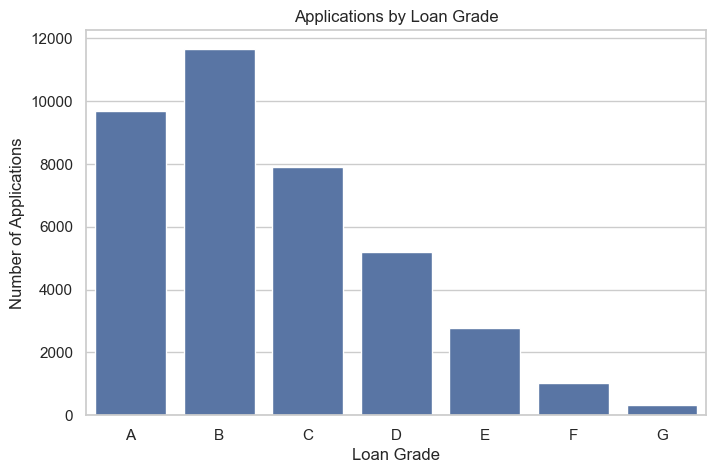

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Loan_Grade",
    order=sorted(df["Loan_Grade"].dropna().unique())
)

plt.title("Applications by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Number of Applications")
plt.show()

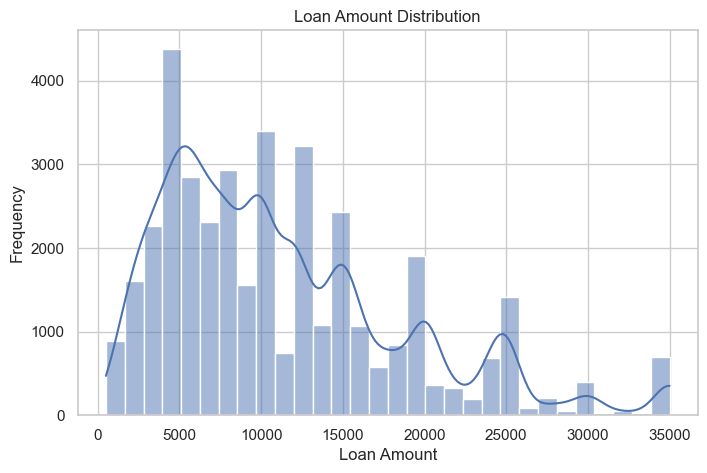

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Loan_Amount",
    bins=30,
    kde=True
)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()

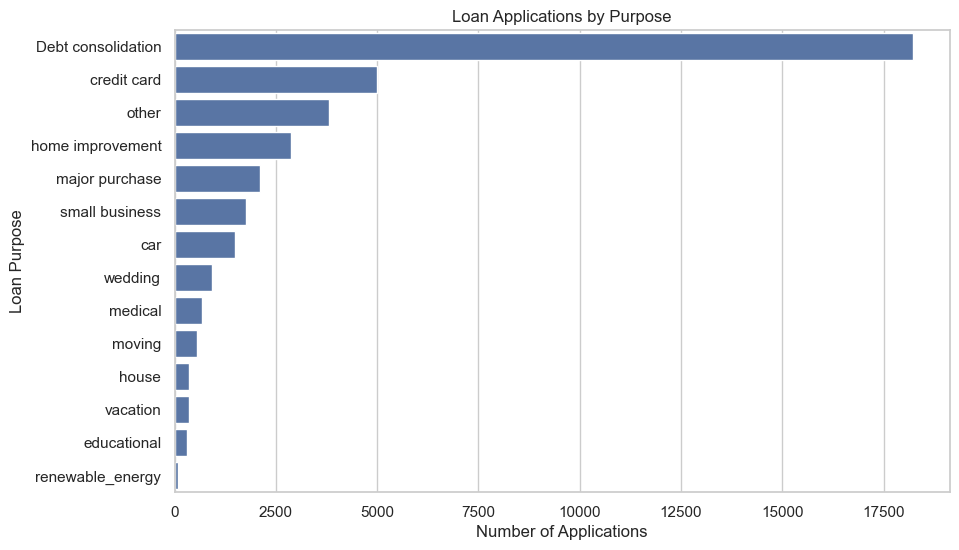

In [34]:
plt.figure(figsize=(10, 6))

purpose_order = df["Purpose"].value_counts().index

sns.countplot(
    data=df,
    y="Purpose",
    order=purpose_order
)

plt.title("Loan Applications by Purpose")
plt.xlabel("Number of Applications")
plt.ylabel("Loan Purpose")
plt.show()

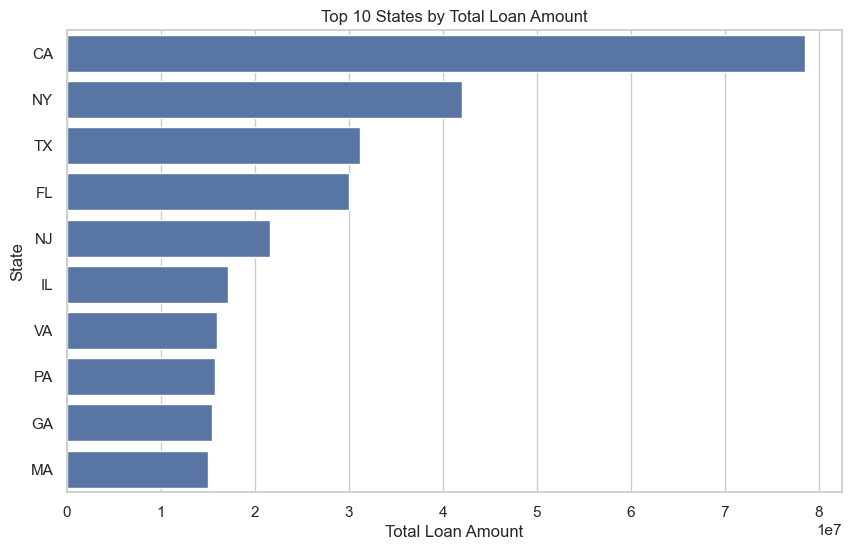

In [35]:
top_states = state_analysis.head(10).reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_states,
    x="Total_Loan_Amount",
    y="State"
)

plt.title("Top 10 States by Total Loan Amount")
plt.xlabel("Total Loan Amount")
plt.ylabel("State")
plt.show()

In [41]:
date_columns = [
    "Issue_Date",
    "Last_Credit_Pull_Date",
    "Last_Payment_Date",
    "Next_Payment_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    df[col] = df[col].dt.strftime("%Y-%m-%d")

print(df[date_columns].head(10))

   Issue_Date Last_Credit_Pull_Date Last_Payment_Date Next_Payment_Date
0  2021-11-02            2021-09-13        2021-04-13        2021-05-13
1  2021-01-01            2021-12-14        2021-01-15        2021-02-15
2  2021-05-01            2021-12-12        2021-09-01        2021-09-02
3  2021-02-25            2021-12-12        2021-12-03        2021-12-04
4  2021-01-01            2021-12-14        2021-01-15        2021-02-15
5  2021-07-17            2021-03-16        2021-12-08        2021-12-09
6  2021-11-19            2021-06-14        2021-12-13        2022-01-13
7  2021-11-06            2021-07-14        2021-07-14        2021-08-14
8  2021-02-09            2021-06-15        2021-12-10        2021-12-11
9  2021-09-02            2021-03-16        2021-03-16        2021-04-16


In [43]:
# Clean currency columns

currency_columns = [
    "Annual_Income",
    "Loan_Amount",
    "Total_Amount_Paid"
]

for col in currency_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[currency_columns].head(10))

print("\nData types:")
print(df[currency_columns].dtypes)

   Annual_Income  Loan_Amount  Total_Amount_Paid
0        30000.0       2500.0             1009.0
1        48000.0       3000.0             3939.0
2        50000.0      12000.0             3522.0
3        42000.0       4500.0             4911.0
4        83000.0       3500.0             3835.0
5        28000.0       8000.0             8637.0
6        94800.0       6000.0             7218.0
7        59000.0       5500.0             6172.0
8       116400.0      24000.0             8650.0
9        36000.0       4125.0             5551.0

Data types:
Annual_Income        float64
Loan_Amount          float64
Total_Amount_Paid    float64
dtype: object


In [44]:
df.to_csv(
    r"D:\Data Analyst\Projects\Bank Loan Portfolio\1. Dataset\Bank_Loan_Python_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
